# MControl: basic microscope control from Python

**On the microscope PC** (the one with the controller and the camera):
```
mc-server.exe                (the real instrument)
mc-server.exe --sim          (simulator: no hardware needed)
```
**Here** (any PC on the LAN), in the MControl folder: `uv sync`, then `uv run jupyter lab examples/basics.ipynb`.

The server is found on the LAN by itself and remembered in `~/.mcontrol.json`, so no address to type. Give one only when there are several servers.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mcontrol import Microscope, Viewer, McError

m = Microscope()       # operator: finds the server by itself (or Microscope("192.168.1.50"))
m

<Microscope vm @ 127.0.0.1>

## 1. Status

In [2]:
s = m.status["server"]
print("camera :", s["camera"]["model"], s["camera"]["w"], "x", s["camera"]["h"], s["camera"]["fmt"])
print("stage  :", m.stage.position, "um")
print("clock  : offset %.3f ms, round trip %.3f ms" % (m.link.offset_ns / 1e6, m.link.rtt_ns / 1e6))

camera : Simulated camera 1296 x 972 bayer_rg8
stage  : (11.111, 0.0, 0.0) um
clock  : offset -0.895 ms, round trip 1.922 ms


## 2. Stage
`goto` is absolute and safe to repeat: after a network glitch the client sends it again by itself.
`move` is relative and is never repeated by itself: if the link drops in the middle you get `E110`. Check `stage.position` before you try again.

In [3]:
print(m.stage.goto(x=0, y=0, z=0))
print(m.stage.goto(x=250, y=-100))    # z stays where it is
print(m.stage.move(dx=50))            # relative
print(m.stage.position)

(0.0, 0.0, 0.0)
(250.0, -100.0, 0.0)
(300.0, -100.0, 0.0)
(300.0, -100.0, 0.0)


Positions snap to whole motor steps (5.556 µm). Sub-µm precision comes from the image (crosses), not from the stage.

## 3. Light and camera

In [4]:
m.light.level = 3                     # 0..5
m.camera.auto_exposure(False)
m.camera.exposure_ms = 15
m.camera.gain = 1
print("light", m.light.level, "| exposure", m.camera.exposure_ms, "ms | gain", m.camera.gain)

light 3 | exposure 15.0 ms | gain 1


## 4. Snap: move, wait until still, take a fresh frame
The frame is the first one whose exposure **started after** the stage stopped (plus `settle_ms`), so there is no motion blur. Its metadata includes the stage position at mid-exposure.

<Frame 125 1296x972 bayer_rg8 at (300.0, 0.0, 0.0) um, lossless 0.54 MB>
xyz (300.0, 0.0, 0.0) | moving False | settled 43.6 ms | exposure 15.0 ms
(972, 1296) uint8 -> (486, 648, 3)


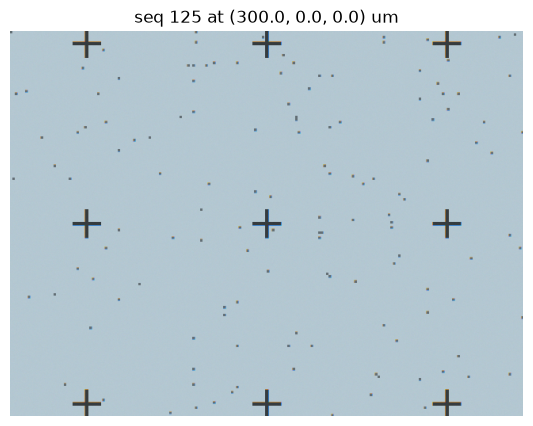

In [5]:
f = m.snap(x=300, y=0, settle_ms=30)
print(f)
print("xyz", f.xyz_um, "| moving", f.moving, "| settled", f.settled_ms, "ms | exposure", f.exposure_ms, "ms")
raw = f.raw()          # sensor array (Bayer), no copy
rgb = f.rgb()          # half size, exact 2x2 superpixel (fast)
print(raw.shape, raw.dtype, "->", rgb.shape)
plt.figure(figsize=(7, 5)); plt.imshow(rgb); plt.title(f"seq {f.seq} at {f.xyz_um} um"); plt.axis("off");

In [6]:
f.save("snap.png")       # colour image + snap.json with all metadata
f.save("snap.npy")       # raw sensor data + snap.json

## 5. Small grid scan (3 × 3)

9 frames in 2.08 s


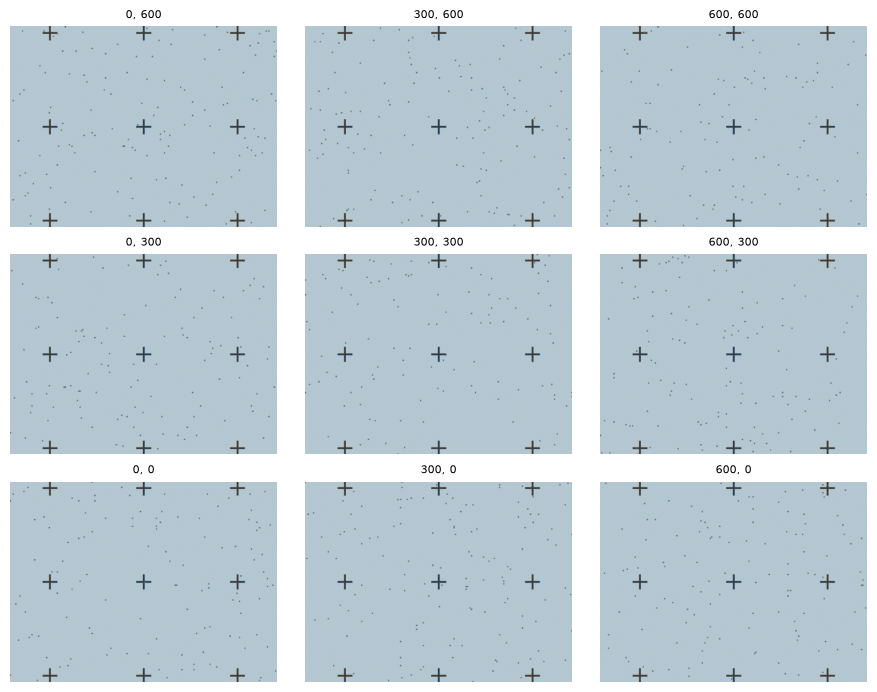

In [7]:
step = 300   # um
tiles = {}
t0 = time.perf_counter()
for j in range(3):
    for i in range(3):
        tiles[i, j] = m.snap(x=i * step, y=j * step, settle_ms=20)
print("9 frames in %.2f s" % (time.perf_counter() - t0))
fig, ax = plt.subplots(3, 3, figsize=(9, 7))
for (i, j), t in tiles.items():
    ax[2 - j, i].imshow(t.rgb()); ax[2 - j, i].set_title(f"{t.xyz_um[0]:.0f}, {t.xyz_um[1]:.0f}", fontsize=8); ax[2 - j, i].axis("off")
plt.tight_layout()

## 6. Live stream
Full-resolution RAW frames flow only while you loop over `live()`; snaps arrive regardless.

In [8]:
n = 0
for f in m.live(seconds=2):
    n += 1
print("%.1f fps, last frame %.1f ms old" % (n / 2, f.age_ms))

25.5 fps, last frame 33.1 ms old


## 7. Events: what is happening on the microscope
Every operator command reaches all clients twice: when it starts and with its result. `describe()` makes a line of text from an event.

In [9]:
from mcontrol import describe
events = []
m.on_event(events.append)
m.light.level = 2
m.snap(dx=100)
time.sleep(0.2)
for e in events:
    if e["event"] == "command":
        print(describe(e))

13:33:21  vm: light level=2  ...
13:33:21  vm: light level=2  ok  (0 ms)
13:33:21  vm: snap dx=100.0  ...
13:33:21  vm: snap dx=100.0  frame 265 at (700.0, 600.0, 0.0)  (109 ms)


## 8. Viewer: read-only, any number of them, light JPEG previews

In [10]:
with Viewer(name="notebook-viewer") as v:
    v.watch(seconds=0.5)                 # prints what the operator does; here: nothing for half a second
    p = v.latest()
    print(p, p.rgb().shape)
    try:
        v.link.call("goto", x=0)
    except McError as e:
        print("viewer cannot move the stage:", e.code, e.msg)

<Frame 283 324x243 jpeg at (700.0, 600.0, 0.0) um, raw 0.01 MB> (243, 324, 3)
viewer cannot move the stage: E102 Read-only: viewers cannot control the microscope: goto


## 9. Errors
Every error is an `McError` with a code: E1xx network, E2xx stage, E3xx controller, E5xx camera, E6xx guard.

In [11]:
try:
    m.laser.mw = 5        # blocked unless mc-server runs with --allow-laser
except McError as e:
    print(e.code, "|", e.msg)
try:
    Microscope()          # second operator
except McError as e:
    print(e.code, "|", e.msg)

E308 | Laser not allowed (start mc-server with --allow-laser)
E103 | Another operator holds the microscope: vm (127.0.0.1)


## 10. Finish
`close()` gives the lease away. The server switches the laser off if an operator vanishes; the guard does the same if the server itself hangs.

In [12]:
m.light.level = 0
m.stage.goto(x=0, y=0)
m.close()